In [2]:
from pathlib import Path

#Project directory
PROJECT_DIR = Path.cwd().parent

# Dataset directory
DATA_DIR = PROJECT_DIR / "data" / "raw" / "watertank"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)

# Check whether the dataset exists
print("Dataset exists:", DATA_DIR.exists())

# List folders and files
for item in DATA_DIR.iterdir():
    print(item.name)

Project directory: c:\Users\User\OneDrive\Desktop\Sonar-Based-Marine-Debris-Detection\Sonar-Based-Marine-Debris-Detection
Dataset directory: c:\Users\User\OneDrive\Desktop\Sonar-Based-Marine-Debris-Detection\Sonar-Based-Marine-Debris-Detection\data\raw\watertank
Dataset exists: True
marine-debris-watertank-release


In [3]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

Matplotlib is building the font cache; this may take a moment.


In [4]:
# Find the image folder
image_folders = list(DATA_DIR.rglob("fls-images"))

# Find the annotation file
annotation_files = list(DATA_DIR.rglob("annotations.json"))

print("Number of image folders:", len(image_folders))
print("Number of annotation files:", len(annotation_files))

# Display their locations
for folder in image_folders:
    print("Image folder:", folder)

for file in annotation_files:
    print("Annotation file:", file)

Number of image folders: 1
Number of annotation files: 1
Image folder: c:\Users\User\OneDrive\Desktop\Sonar-Based-Marine-Debris-Detection\Sonar-Based-Marine-Debris-Detection\data\raw\watertank\marine-debris-watertank-release\fls-images
Annotation file: c:\Users\User\OneDrive\Desktop\Sonar-Based-Marine-Debris-Detection\Sonar-Based-Marine-Debris-Detection\data\raw\watertank\marine-debris-watertank-release\fls-images\annotations.json


In [5]:
# Get the image directory
IMAGE_DIR = image_folders[0]

# Supported image formats
image_extensions = [".png", ".jpg", ".jpeg"]

# Collect all image files
image_files = [
    file for file in IMAGE_DIR.iterdir()
    if file.suffix.lower() in image_extensions
]

# Count the images
print("Total number of sonar images:", len(image_files))

# Display the first 10 filenames
print("\nFirst 10 images:")

for image in image_files[:10]:
    print(image.name)

Total number of sonar images: 1868

First 10 images:
marine-debris-aris3k-0.png
marine-debris-aris3k-1.png
marine-debris-aris3k-10.png
marine-debris-aris3k-100.png
marine-debris-aris3k-1000.png
marine-debris-aris3k-1001.png
marine-debris-aris3k-1002.png
marine-debris-aris3k-1003.png
marine-debris-aris3k-1004.png
marine-debris-aris3k-1005.png


In [6]:
from PIL import Image

# Select the first image
sample_image_path = image_files[0]

# Open the image
sample_image = Image.open(sample_image_path)

# Display image properties
print("Image name:", sample_image_path.name)
print("Image format:", sample_image.format)
print("Image dimensions:", sample_image.size)
print("Image mode:", sample_image.mode)

Image name: marine-debris-aris3k-0.png
Image format: PNG
Image dimensions: (500, 605)
Image mode: RGBA


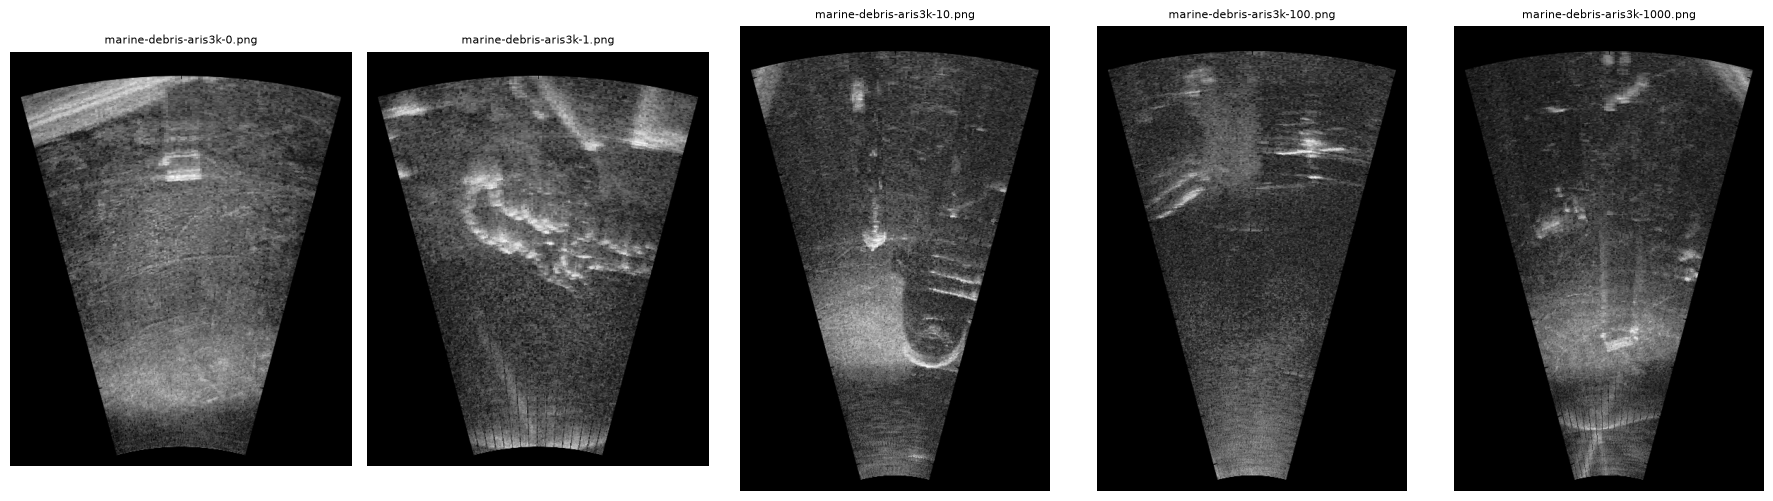

In [7]:
import matplotlib.pyplot as plt

# Create a figure with five subplots
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for ax, image_path in zip(axes, image_files[:5]):

    # Open image
    image = Image.open(image_path)

    # Display image
    ax.imshow(image, cmap="gray")

    ax.set_title(image_path.name, fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
import json

# Locate the annotation file
ANNOTATION_PATH = annotation_files[0]

# Open and load JSON data
with open(ANNOTATION_PATH, "r") as file:
    annotations = json.load(file)

# Inspect the structure
print("Annotation data type:", type(annotations))

if isinstance(annotations, dict):
    print("Top-level keys:", annotations.keys())

elif isinstance(annotations, list):
    print("Number of records:", len(annotations))

# Display a small sample
print("\nSample annotation data:")
print(str(annotations)[:3000])

Annotation data type: <class 'dict'>
Top-level keys: dict_keys(['marine-debris-aris3k-638.png', 'marine-debris-aris3k-391.png', 'marine-debris-aris3k-669.png', 'marine-debris-aris3k-445.png', 'marine-debris-aris3k-1193.png', 'marine-debris-aris3k-643.png', 'marine-debris-aris3k-1526.png', 'marine-debris-aris3k-1512.png', 'marine-debris-aris3k-1600.png', 'marine-debris-aris3k-817.png', 'marine-debris-aris3k-1087.png', 'marine-debris-aris3k-307.png', 'marine-debris-aris3k-1819.png', 'marine-debris-aris3k-830.png', 'marine-debris-aris3k-1112.png', 'marine-debris-aris3k-1248.png', 'marine-debris-aris3k-1783.png', 'marine-debris-aris3k-537.png', 'marine-debris-aris3k-339.png', 'marine-debris-aris3k-1636.png', 'marine-debris-aris3k-1401.png', 'marine-debris-aris3k-1381.png', 'marine-debris-aris3k-544.png', 'marine-debris-aris3k-1734.png', 'marine-debris-aris3k-688.png', 'marine-debris-aris3k-1652.png', 'marine-debris-aris3k-1463.png', 'marine-debris-aris3k-1367.png', 'marine-debris-aris3k-67

ANALYSING THE DATASET

In [9]:
# Inspect the structure of our annotation data

if isinstance(annotations, dict):

    for key, value in annotations.items():

        print(f"\nKey: {key}")
        print("Type:", type(value))

        if isinstance(value, list):
            print("Number of items:", len(value))

            if len(value) > 0:
                print("First item:", value[0])

        elif isinstance(value, dict):
            print("Nested keys:", list(value.keys())[:20])

        else:
            print("Value:", value)

elif isinstance(annotations, list):

    print("Total records:", len(annotations))

    if len(annotations) > 0:
        print("First record:")
        print(annotations[0])


Key: marine-debris-aris3k-638.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-391.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-669.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-445.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-1193.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-643.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-1526.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-1512.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-1600.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-817.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-1087.png
Type: <class 'dict'>
Nested keys: ['bounding-boxes']

Key: marine-debris-aris3k-

a) inspect bounding boxes

In [10]:
# Get the first image filename
first_image_name = next(iter(annotations))

# Get its annotation
first_image_annotation = annotations[first_image_name]

print("Image name:", first_image_name)

print("\nAnnotation:")
print(first_image_annotation)

Image name: marine-debris-aris3k-638.png

Annotation:
{'bounding-boxes': [{'class': 'can', 'width': 61, 'height': 51, 'top-left-x': 123, 'top-left-y': 399, 'class-id': 0}]}


In [11]:
# Extract bounding boxes
first_boxes = first_image_annotation["bounding-boxes"]

print("Bounding-box data type:", type(first_boxes))

print("\nBounding-box contents:")
print(first_boxes)

Bounding-box data type: <class 'list'>

Bounding-box contents:
[{'class': 'can', 'width': 61, 'height': 51, 'top-left-x': 123, 'top-left-y': 399, 'class-id': 0}]


In [12]:
print("Image:", first_image_name)

print("Number of bounding boxes:", len(first_boxes))

Image: marine-debris-aris3k-638.png
Number of bounding boxes: 1


In [13]:
if len(first_boxes) > 0:

    first_box = first_boxes[0]

    print("First bounding box:")
    print(first_box)

    print("\nData type:", type(first_box))

    if isinstance(first_box, dict):
        print("Available fields:", first_box.keys())

First bounding box:
{'class': 'can', 'width': 61, 'height': 51, 'top-left-x': 123, 'top-left-y': 399, 'class-id': 0}

Data type: <class 'dict'>
Available fields: dict_keys(['class', 'width', 'height', 'top-left-x', 'top-left-y', 'class-id'])


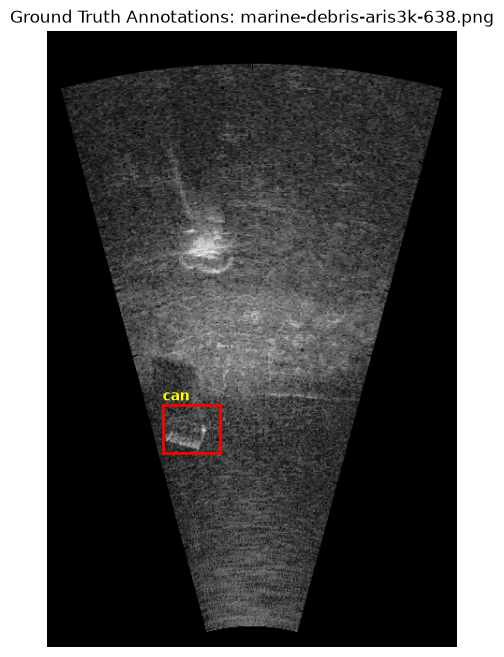

In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Get the first image
image_path = IMAGE_DIR / first_image_name

# Load image
image = Image.open(image_path).convert("RGB")

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Display sonar image
ax.imshow(image)

# Draw bounding boxes
for box in first_boxes:

    x = box["top-left-x"]
    y = box["top-left-y"]
    width = box["width"]
    height = box["height"]

    # Create rectangle
    rectangle = patches.Rectangle(
        (x, y),
        width,
        height,
        linewidth=2,
        edgecolor="red",
        facecolor="none"
    )

    ax.add_patch(rectangle)

    # Add class label
    ax.text(
        x,
        y - 5,
        box["class"],
        color="yellow",
        fontsize=10,
        weight="bold"
    )

ax.set_title(f"Ground Truth Annotations: {first_image_name}")
ax.axis("off")

plt.show()

b) calculate dataset statistics

In [16]:
from collections import Counter

# Store all annotated object classes
class_counts = Counter()

# Count total bounding boxes
total_boxes = 0

# Count images with and without annotations
images_with_boxes = 0
images_without_boxes = 0

# Loop through all annotations
for image_name, image_data in annotations.items():

    boxes = image_data["bounding-boxes"]

    if len(boxes) > 0:
        images_with_boxes += 1
    else:
        images_without_boxes += 1

    # Count each bounding box and its class
    for box in boxes:
        total_boxes += 1
        class_counts[box["class"]] += 1


# Display results
print("DATASET ANNOTATION SUMMARY")
print("-" * 35)

print("Total annotated images:", len(annotations))
print("Images with bounding boxes:", images_with_boxes)
print("Images without bounding boxes:", images_without_boxes)
print("Total annotated objects:", total_boxes)

print("\nOBJECTS PER CLASS")
print("-" * 35)

for class_name, count in class_counts.most_common():
    print(f"{class_name}: {count}")

DATASET ANNOTATION SUMMARY
-----------------------------------
Total annotated images: 1868
Images with bounding boxes: 1868
Images without bounding boxes: 0
Total annotated objects: 2364

OBJECTS PER CLASS
-----------------------------------
bottle: 449
can: 367
drink-carton: 349
tire: 331
chain: 226
valve: 208
propeller: 137
hook: 133
shampoo-bottle: 99
standing-bottle: 65


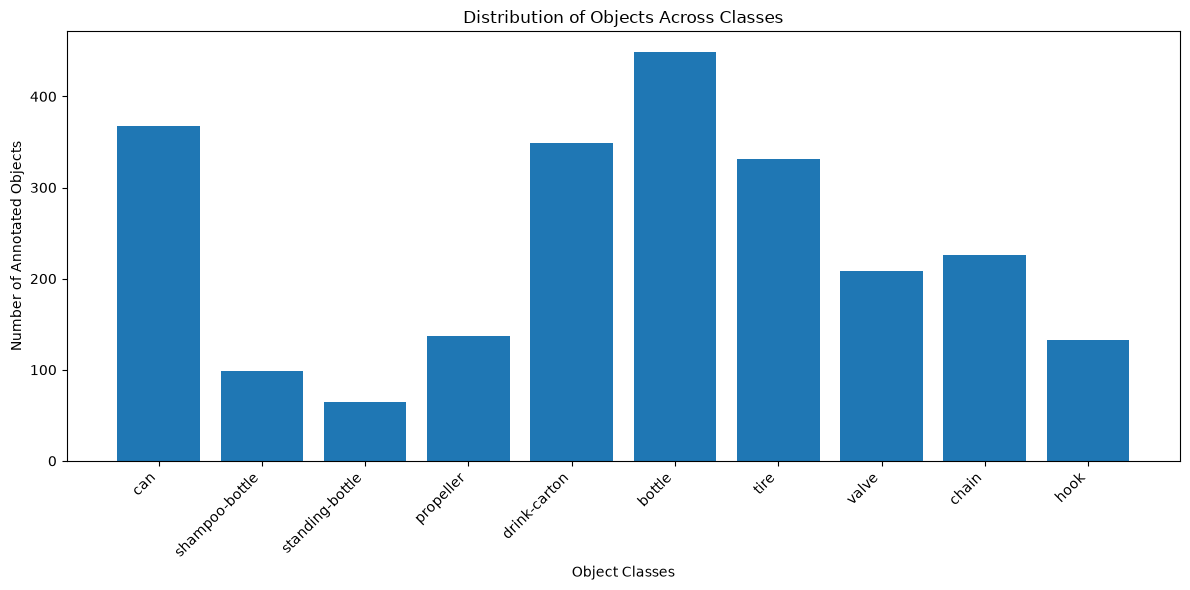

In [ ]:
#visualise the class distribution
import matplotlib.pyplot as plt

# Extract class names and their counts
classes = list(class_counts.keys())
counts = list(class_counts.values())

# Create bar chart
plt.figure(figsize=(12, 6))

plt.bar(classes, counts)

plt.title("Distribution of Objects Across Classes")
plt.xlabel("Object Classes")
plt.ylabel("Number of Annotated Objects")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

c) validate class ids

In [18]:
# Create a dictionary to store class names and their IDs
class_id_mapping = {}

# Store inconsistencies
inconsistent_classes = []

# Check every annotation
for image_name, image_data in annotations.items():

    for box in image_data["bounding-boxes"]:

        class_name = box["class"]
        class_id = box["class-id"]

        # Check whether this class has been encountered before
        if class_name not in class_id_mapping:

            class_id_mapping[class_name] = class_id

        # Check whether the class has a different ID
        elif class_id_mapping[class_name] != class_id:

            inconsistent_classes.append({
                "image": image_name,
                "class": class_name,
                "expected_id": class_id_mapping[class_name],
                "actual_id": class_id
            })


# Display results
print("CLASS ID MAPPING")
print("-" * 35)

for class_name, class_id in sorted(
    class_id_mapping.items(),
    key=lambda item: item[1]
):
    print(f"{class_id}: {class_name}")

print("\nINCONSISTENCIES:", len(inconsistent_classes))

if inconsistent_classes:
    print(inconsistent_classes[:10])
else:
    print("All classes have consistent IDs.")

CLASS ID MAPPING
-----------------------------------
0: can
1: bottle
2: drink-carton
3: chain
4: propeller
5: tire
6: hook
7: valve
8: shampoo-bottle
9: standing-bottle

INCONSISTENCIES: 0
All classes have consistent IDs.


In [19]:
from PIL import Image

# Counters for bounding-box validation
valid_boxes = 0
invalid_boxes = 0

invalid_box_details = []

# Check all annotated images
for image_name, image_data in annotations.items():

    image_path = IMAGE_DIR / image_name

    # Get image dimensions
    with Image.open(image_path) as image:
        image_width, image_height = image.size

    # Check every bounding box
    for box in image_data["bounding-boxes"]:

        x = box["top-left-x"]
        y = box["top-left-y"]
        width = box["width"]
        height = box["height"]

        # Check whether the box fits inside the image
        if (
            x >= 0 and
            y >= 0 and
            width > 0 and
            height > 0 and
            x + width <= image_width and
            y + height <= image_height
        ):
            valid_boxes += 1

        else:
            invalid_boxes += 1

            invalid_box_details.append({
                "image": image_name,
                "box": box,
                "image_width": image_width,
                "image_height": image_height
            })


# Display results
print("BOUNDING BOX VALIDATION")
print("-" * 35)

print("Valid bounding boxes:", valid_boxes)
print("Invalid bounding boxes:", invalid_boxes)

if invalid_boxes > 0:
    print("\nExamples of invalid boxes:")
    for item in invalid_box_details[:5]:
        print(item)
else:
    print("All bounding boxes are within image boundaries.")

BOUNDING BOX VALIDATION
-----------------------------------
Valid bounding boxes: 2364
Invalid bounding boxes: 0
All bounding boxes are within image boundaries.


e) image verification

In [21]:
# Get all image filenames referenced in annotations
annotated_images = set(annotations.keys())

# Get all actual image filenames in IMAGE_DIR
available_images = {
    image.name
    for image in IMAGE_DIR.iterdir()
    if image.is_file()
}

# Compare both sets
missing_images = annotated_images - available_images
unannotated_images = available_images - annotated_images

# Display results
print("IMAGE FILE VERIFICATION")
print("-" * 35)

print("Images referenced in annotations:", len(annotated_images))
print("Images available in folder:", len(available_images))
print("Missing image files:", len(missing_images))
print("Images without annotations:", len(unannotated_images))

if missing_images:
    print("\nMissing image examples:", list(missing_images)[:10])
else:
    print("\nAll annotated images exist in the image folder.")

IMAGE FILE VERIFICATION
-----------------------------------
Images referenced in annotations: 1868
Images available in folder: 1869
Missing image files: 0
Images without annotations: 1

All annotated images exist in the image folder.


In [23]:
# Define valid image extensions
image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

# Get annotated image filenames
annotated_images = set(annotations.keys())

# Get only actual image files
available_images = {
    image.name
    for image in IMAGE_DIR.iterdir()
    if image.is_file() and image.suffix.lower() in image_extensions
}

# Compare both sets
missing_images = annotated_images - available_images
unannotated_images = available_images - annotated_images

# Display results
print("IMAGE FILE VERIFICATION")
print("-" * 35)

print("Images referenced in annotations:", len(annotated_images))
print("Actual image files:", len(available_images))
print("Missing image files:", len(missing_images))
print("Images without annotations:", len(unannotated_images))

if missing_images:
    print("\nMissing images:", list(missing_images)[:10])
else:
    print("\nAll annotated images exist in the image folder.")

if unannotated_images:
    print("\nUnannotated images:", list(unannotated_images))

IMAGE FILE VERIFICATION
-----------------------------------
Images referenced in annotations: 1868
Actual image files: 1868
Missing image files: 0
Images without annotations: 0

All annotated images exist in the image folder.
